# Регресія тривалості ДТП — IsotonicRegression

*Дані з `regression_data_preparation.ipynb`; ціль `Log_Duration = log1p(Duration_Minutes)`.*

`pyspark.ml.regression.IsotonicRegression` будує **монотонну** (неспадну або незростаючу) кусково-лінійну функцію від **однієї** ознаки, тому на 247 ознаках напряму її не застосувати. Порівнюємо два сімейства:

| Сімейство | Що це |
|---|---|
| `IsotonicRegression` | ізотонічна регресія на одній ознаці; CV обирає ознаку (із топ-K за |Spearman|) і напрямок (`isotonic=True/False`) |
| `LinearThenIsotonic` | `Pipeline`: `LinearRegression` на всіх ознаках дає скалярний скор, на ньому `IsotonicRegression` монотонно калібрує прогноз |

## Етап 0. Середовище

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, Bucketizer
from pyspark.ml.regression import IsotonicRegression, LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.stat import Correlation

ROOT = Path.cwd() if (Path.cwd() / 'main.py').exists() else Path.cwd().parent
DATA = ROOT / 'data' / 'processed' / 'regression'
OUT = ROOT / 'data' / 'models'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
TUNE_ROWS = int(os.environ.get('TUNE_ROWS', '80000'))
TRAIN_FRACTION = float(os.environ.get('TRAIN_FRACTION', '1'))
SHAP_ROWS = int(os.environ.get('SHAP_ROWS', '3000'))
SCREEN_ROWS = int(os.environ.get('SCREEN_ROWS', '20000'))   # рядків для відбору ознак за Spearman
TOP_K = int(os.environ.get('TOP_K', '8'))                   # скільки ознак іде в CV для 1D-ізотоніки
DRIVER_MEMORY = os.environ.get('DRIVER_MEMORY', '6g')       # у попередньому ноутбуці був OOM на 1g
CV_FOLDS = 5
assert (DATA / 'metadata.json').exists(), 'Спочатку завершіть regression_data_preparation.ipynb'
os.environ['PYSPARK_PYTHON'] = sys.executable
# spark.driver.memory діє лише якщо SparkSession ще не створено: після зміни перезапустіть kernel
spark = (SparkSession.builder.appName('US-Accidents-regression-isotonic')
         .master('local[2]')
         .config('spark.driver.memory', DRIVER_MEMORY)
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.driver.maxResultSize', '1g')
         .config('spark.ui.showConsoleProgress', 'false').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
print('Spark', spark.version)

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark 4.2.1


## Етап 1. Завантаження та огляд train / valid / test

In [2]:
meta = json.loads((DATA / 'metadata.json').read_text(encoding='utf-8'))
FEATURES = meta['feature_names']
SAFE = [f'f{i}' for i in range(len(FEATURES))]

def read_split(name):
    df = spark.read.parquet(str(DATA / name))
    return df.select('ID', F.col('Log_Duration').cast('double').alias('label'),
                     F.col('Duration_Minutes').cast('double').alias('minutes'),
                     *[F.col('`'+col.replace('`','``')+'`').cast('double').alias(safe)
                       for col, safe in zip(FEATURES, SAFE)])
raw = {s: read_split(s) for s in ('train','valid','test')}
if TRAIN_FRACTION < 1:
    raw['train'] = raw['train'].sample(False, TRAIN_FRACTION, SEED)
for name, df in raw.items():
    print(name, 'columns:', len(df.columns), 'sample:')
    display(df.select('label','minutes',*SAFE[:4]).limit(4).toPandas())

train columns: 247 sample:


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,minutes,f0,f1,f2,f3
0,4.110874,60.00,-0.364908,-1.367240,-0.557499,1.399576
1,3.410157,29.27,0.545562,0.018898,-0.557499,1.825403
2,4.119362,60.52,1.133219,0.417321,-0.557499,0.122094
3,3.827554,44.95,-0.009973,0.465663,-0.557499,1.186662


valid columns: 247 sample:


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,minutes,f0,f1,f2,f3
0,4.699753,108.92,-0.236919,0.783983,-0.557499,0.335007
1,4.067658,57.42,-0.392088,0.869631,-0.557499,0.867292
2,4.110874,60.00,-0.406671,-1.351524,-0.557499,-0.085497
3,3.842244,45.63,-1.197667,-0.163081,-0.557499,0.760835


test columns: 247 sample:


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,minutes,f0,f1,f2,f3
0,4.678235,106.58,-0.077927,0.938835,-0.557499,0.601149
1,3.414443,29.40,0.508761,0.287952,-0.557499,0.281779
2,3.828641,45.00,-0.437945,-1.333911,-0.557499,0.239196
3,5.473404,237.27,0.282688,0.998558,-0.557499,0.122094


In [3]:
assembler = VectorAssembler(inputCols=SAFE, outputCol='features', handleInvalid='error')

data = {s: assembler.transform(df.filter(F.col('label') > 0))
        .select('ID', 'label', 'minutes', 'features')
        .persist(StorageLevel.MEMORY_AND_DISK)
        for s, df in raw.items()}
counts = {s: d.count() for s,d in data.items()}
print('Кількість записів:', counts)
for s,d in data.items():
    display(d.select('label','minutes').describe().toPandas().assign(split=s))

Кількість записів: {'train': 4496355, 'valid': 642217, 'test': 1282718}


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,summary,label,minutes,split
0,count,4496355,4496355,train
1,mean,4.171715825263084,84.93995044205391,train
2,stddev,0.7090692169755293,82.066547438215,train
3,min,0.7975071958841881,1.22,train
4,max,6.610022870676855,741.5,train


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,summary,label,minutes,split
0,count,642217,642217,valid
1,mean,4.169323671585825,84.69043192565663,valid
2,stddev,0.7083738755160895,81.74647069992469,valid
3,min,1.6094379124341003,4.0,valid
4,max,6.610022870676855,741.5,valid


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,summary,label,minutes,split
0,count,1282718,1282718,test
1,mean,4.170339048138543,84.82113913580874,test
2,stddev,0.7092788299415512,81.85619321409399,test
3,min,1.0715836162801904,1.92,test
4,max,6.610022870676855,741.5,test


## Етап 2. Стратифікована підвибірка, відбір ознак, 5-fold CV, RMSE та MAE

In [4]:
edges = sorted(set(data['train'].approxQuantile('label', [i / 10 for i in range(1, 10)], 0.001)))
bucketizer = Bucketizer(splits=[-float('inf'), *edges, float('inf')], inputCol='label', outputCol='stratum')
stratified = bucketizer.transform(data['train'])
frac = min(1.0, TUNE_ROWS / max(1, counts['train']))
strata = list(range(len(edges)+1))
tune = (stratified.sampleBy('stratum', {float(x):frac for x in strata}, SEED)
        .withColumn('_r', F.rand(SEED))
        .withColumn('fold', ((F.row_number().over(Window.partitionBy('stratum').orderBy('_r'))-1) % CV_FOLDS).cast('int'))
        .drop('_r','stratum').persist(StorageLevel.MEMORY_AND_DISK))
tune_n = tune.count()
print('CV sample:', tune_n)

CV sample: 80267


### Відбір кандидатів для 1D-ізотоніки

Ізотонічна регресія ловить будь-який монотонний зв'язок, тому ознаки ранжуємо за **|Spearman|** з ціллю на підвибірці `tune` (лише train; valid/test не використовуються). Перебирати всі 247 ознак у CV задорого, тому в сітку йде топ-`TOP_K`.

In [5]:
screen = tune.select('features', 'label').sample(False, min(1.0, SCREEN_ROWS / max(1, tune_n)), SEED).limit(SCREEN_ROWS)
xy = VectorAssembler(inputCols=['features', 'label'], outputCol='xy').transform(screen).select('xy')
spearman = np.nan_to_num(Correlation.corr(xy, 'xy', 'spearman').head()[0].toArray()[-1, :-1])   # NaN -> 0 для константних ознак
RANK = (pd.DataFrame({'index': range(len(FEATURES)), 'feature': FEATURES, 'spearman': spearman})
        .assign(abs_spearman=lambda d: d['spearman'].abs())
        .sort_values('abs_spearman', ascending=False).reset_index(drop=True))
TOP = RANK.head(TOP_K)
display(TOP.round(4))

,index,feature,spearman,abs_spearman
0,202,"Distance(mi) in [0, 0.00995)",-0.3699,0.3699
1,2,Distance(mi),0.3625,0.3625
2,97,Source_Year=Source2_2018,-0.3177,0.3177
3,20,TE_Street_t_logdur,0.3054,0.3054
4,96,Source_Year=Source1_2021,0.2755,0.2755
5,23,TE_Zip_t_logdur,0.2599,0.2599
6,100,Source_Year=Source2_2017,-0.2509,0.2509
7,21,TE_City_t_logdur,0.2496,0.2496


In [6]:
iso = IsotonicRegression(featuresCol='features', labelCol='label', predictionCol='prediction')

# regParam=1e-6 у base: мінімальна регуляризація, щоб нормальні рівняння не ламались на колінеарних ознаках
lin = LinearRegression(featuresCol='features', labelCol='label', predictionCol='lin_score', regParam=1e-6, elasticNetParam=0.0)
to_vec = VectorAssembler(inputCols=['lin_score'], outputCol='lin_vec')
iso2 = IsotonicRegression(featuresCol='lin_vec', labelCol='label', predictionCol='prediction', isotonic=True)
pipe = Pipeline(stages=[lin, to_vec, iso2])

FAMILIES = {'IsotonicRegression': iso, 'LinearThenIsotonic': pipe}
GRID = {
    'IsotonicRegression': (ParamGridBuilder()
                           .addGrid(iso.featureIndex, [int(i) for i in TOP['index']])
                           .addGrid(iso.isotonic, [True, False]).build()),
    'LinearThenIsotonic': (ParamGridBuilder()
                           .addGrid(lin.regParam, [1e-4, 1e-3, 1e-2, 1e-1, 1.0]).build()),
}
def evaluate(predictions):
    row = predictions.select(F.avg(F.pow(F.col('prediction')-F.col('label'),2)).alias('mse'),
          F.avg(F.abs(F.col('prediction')-F.col('label'))).alias('mae'),
          F.avg(F.pow(F.expm1(F.col('prediction'))-F.col('minutes'),2)).alias('mse_min'),
          F.avg(F.abs(F.expm1(F.col('prediction'))-F.col('minutes'))).alias('mae_min')).first()
    return {'RMSE (log)': float(np.sqrt(row.mse)), 'MAE (log)':float(row.mae),
            'RMSE (хв)':float(np.sqrt(row.mse_min)), 'MAE (хв)':float(row.mae_min)}

In [7]:
BEST = {}
CV_TABLES = {}
for fam, estimator in FAMILIES.items():
    print('Підбір:', fam, flush=True)
    cv = CrossValidator(estimator=estimator, estimatorParamMaps=GRID[fam],
            evaluator=RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName='rmse'),
            numFolds=CV_FOLDS, foldCol='fold', parallelism=1, seed=SEED)
    cvfit = cv.fit(tune)
    t = pd.DataFrame([{p.name:v for p,v in pm.items()} for pm in GRID[fam]])
    t['CV RMSE (log)'] = cvfit.avgMetrics
    if fam == 'IsotonicRegression':
        t['feature'] = t['featureIndex'].map(lambda i: FEATURES[int(i)])
    CV_TABLES[fam] = t.sort_values('CV RMSE (log)')
    BEST[fam] = GRID[fam][int(np.argmin(cvfit.avgMetrics))]
    display(CV_TABLES[fam])

best_idx = int(BEST['IsotonicRegression'][iso.featureIndex])
print('1D-ізотоніка: найкраща ознака =', FEATURES[best_idx], '| isotonic =', BEST['IsotonicRegression'][iso.isotonic])

Підбір: IsotonicRegression


,featureIndex,isotonic,CV RMSE (log),feature
2,2,True,0.637874,Distance(mi)
1,202,False,0.657456,"Distance(mi) in [0, 0.00995)"
6,20,True,0.673587,TE_Street_t_logdur
5,97,False,0.678986,Source_Year=Source2_2018
10,23,True,0.679744,TE_Zip_t_logdur
8,96,True,0.680955,Source_Year=Source1_2021
14,21,True,0.681623,TE_City_t_logdur
13,100,False,0.689294,Source_Year=Source2_2017
11,23,False,0.708566,TE_Zip_t_logdur
12,100,True,0.708566,Source_Year=Source2_2017


Підбір: LinearThenIsotonic


,regParam,CV RMSE (log)
2,0.0100,0.565969
0,0.0001,0.566095
1,0.0010,0.566139
3,0.1000,0.566759
4,1.0000,0.580021


1D-ізотоніка: найкраща ознака = Distance(mi) | isotonic = True


## Етап 3. Навчання base та tuned на повному train

`base` — параметри за замовчуванням (для 1D: `featureIndex=0`, `isotonic=True`; для pipeline: `LinearRegression` з `regParam=1e-6`), `tuned` — найкращі параметри з CV.

In [8]:
MODELS = {}
FIT_TIME = {}
for fam, est in FAMILIES.items():
    for kind, params in [('base', {}), ('tuned', BEST[fam])]:
        name = fam+' '+kind
        print('Навчання', name, flush=True)
        start = time.time()
        MODELS[name] = est.copy(params).fit(data['train'])
        FIT_TIME[name] = round(time.time()-start,1)
print('Час навчання, с:', FIT_TIME)
def metrics_table(split):
    results = {}
    for name,model in MODELS.items():
        results[name] = evaluate(model.transform(data[split]))
    return pd.DataFrame.from_dict(results,orient='index').sort_values('RMSE (log)')
TRAIN_RESULTS = metrics_table('train')
display(TRAIN_RESULTS.round(4))

Навчання IsotonicRegression base
Навчання IsotonicRegression tuned
Навчання LinearThenIsotonic base
Навчання LinearThenIsotonic tuned
Час навчання, с: {'IsotonicRegression base': 86.8, 'IsotonicRegression tuned': 84.6, 'LinearThenIsotonic base': 68.1, 'LinearThenIsotonic tuned': 66.0}


,RMSE (log),MAE (log),RMSE (хв),MAE (хв)
LinearThenIsotonic tuned,0.5660,0.4226,72.8770,37.5732
LinearThenIsotonic base,0.5660,0.4226,72.8914,37.5845
IsotonicRegression tuned,0.6388,0.4912,78.2406,42.0457
IsotonicRegression base,0.7067,0.5807,84.4893,47.9583


## Етап 4. Валідація, вибір лідерів та графіки train/valid

In [9]:
VALID_RESULTS = metrics_table('valid')
LEADERS = {fam: VALID_RESULTS.loc[[x for x in MODELS if x.startswith(fam+' ')] , 'RMSE (log)'].idxmin()
           for fam in FAMILIES}
print('Лідери:', LEADERS)
display(VALID_RESULTS.round(4))
summary = pd.concat({'train':TRAIN_RESULTS,'valid':VALID_RESULTS},names=['split','model'])
display(summary.round(4))

Лідери: {'IsotonicRegression': 'IsotonicRegression tuned', 'LinearThenIsotonic': 'LinearThenIsotonic tuned'}


,RMSE (log),MAE (log),RMSE (хв),MAE (хв)
LinearThenIsotonic tuned,0.5656,0.4225,72.5051,37.4674
LinearThenIsotonic base,0.5656,0.4225,72.5250,37.4792
IsotonicRegression tuned,0.6391,0.4913,77.9525,41.9334
IsotonicRegression base,0.7060,0.5804,84.1179,47.8006


RMSE (log)  MAE (log)  RMSE (хв)  MAE (хв)
split model                                                               
train LinearThenIsotonic tuned      0.5660     0.4226    72.8770   37.5732
      LinearThenIsotonic base       0.5660     0.4226    72.8914   37.5845
      IsotonicRegression tuned      0.6388     0.4912    78.2406   42.0457
      IsotonicRegression base       0.7067     0.5807    84.4893   47.9583
valid LinearThenIsotonic tuned      0.5656     0.4225    72.5051   37.4674
      LinearThenIsotonic base       0.5656     0.4225    72.5250   37.4792
      IsotonicRegression tuned      0.6391     0.4913    77.9525   41.9334
      IsotonicRegression base       0.7060     0.5804    84.1179   47.8006

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recomm

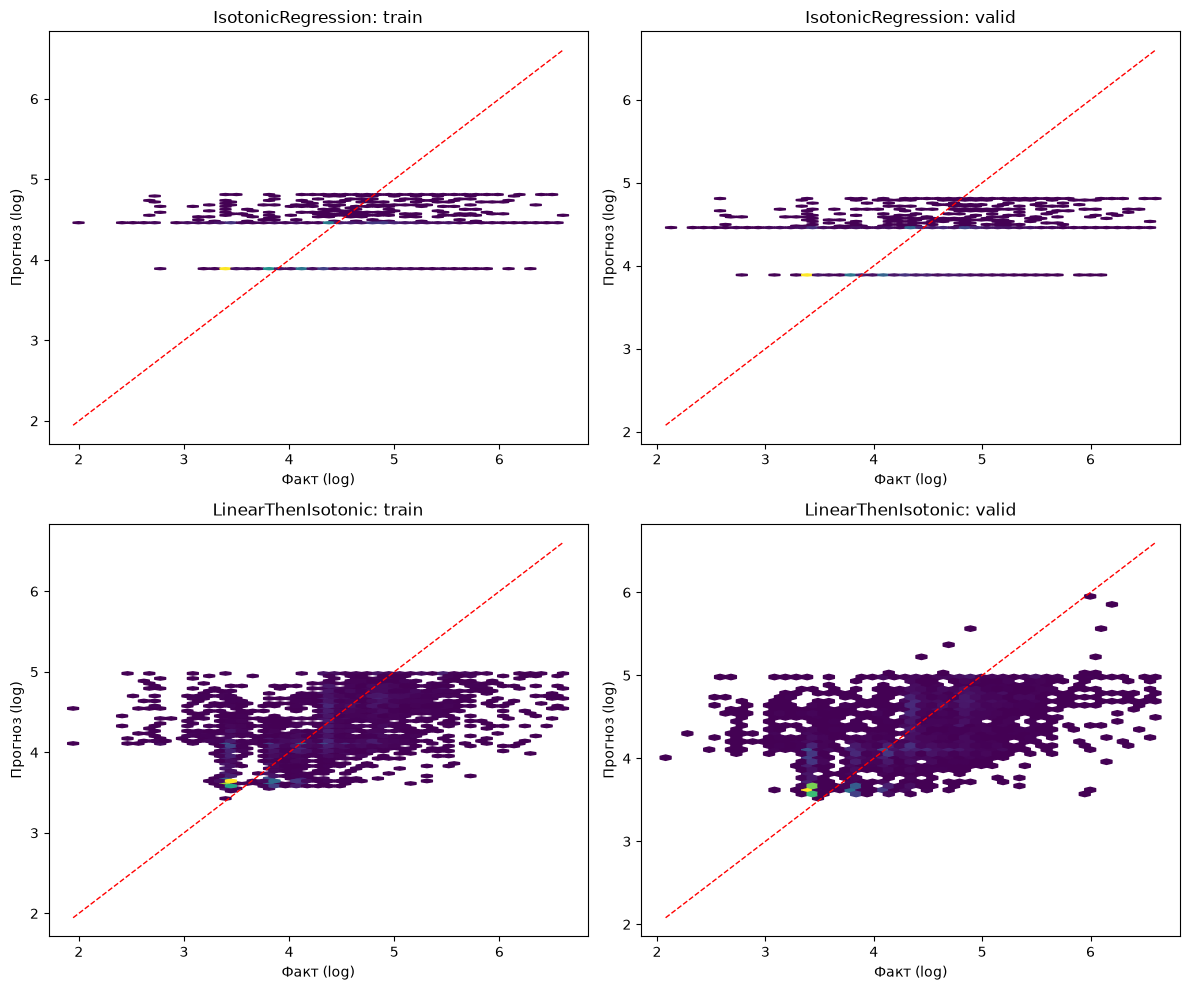

In [10]:
def prediction_sample(model, split, size=4000):
    d = model.transform(data[split]).select('label','prediction')
    return d.sample(False,min(1.,size/max(1,counts[split])),SEED).limit(size).toPandas()
fig, axs = plt.subplots(2,2,figsize=(12,10))
for i,(fam,name) in enumerate(LEADERS.items()):
    for j,split in enumerate(['train','valid']):
        p = prediction_sample(MODELS[name],split)
        ax=axs[i,j]
        ax.hexbin(p['label'],p['prediction'],gridsize=45,mincnt=1,cmap='viridis')
        lim=[min(p.min()),max(p.max())]
        ax.plot(lim,lim,'r--',lw=1)
        ax.set(title=f'{fam}: {split}',xlabel='Факт (log)',ylabel='Прогноз (log)')
plt.tight_layout(); plt.show()

## Етап 5. Фінальна оцінка на test

,RMSE (log),MAE (log),RMSE (хв),MAE (хв)
IsotonicRegression,0.6391,0.4915,78.0209,41.9950
LinearThenIsotonic,0.5665,0.4229,72.6322,37.5305


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recomm

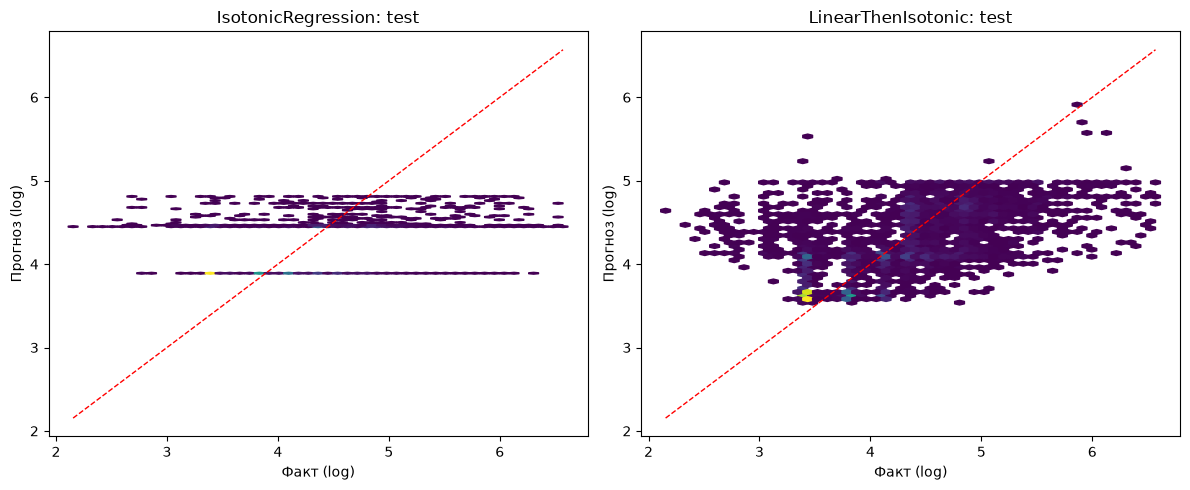

In [11]:
TEST_RESULTS = pd.DataFrame.from_dict(
    {fam:evaluate(MODELS[name].transform(data['test'])) for fam,name in LEADERS.items()},orient='index')
display(TEST_RESULTS.round(4))
fig,axs=plt.subplots(1,2,figsize=(12,5))
for ax,(fam,name) in zip(axs,LEADERS.items()):
    p=prediction_sample(MODELS[name],'test')
    ax.hexbin(p['label'],p['prediction'],gridsize=50,mincnt=1,cmap='viridis')
    lim=[min(p.min()),max(p.max())]
    ax.plot(lim,lim,'r--',lw=1)
    ax.set(title=f'{fam}: test',xlabel='Факт (log)',ylabel='Прогноз (log)')
plt.tight_layout();plt.show()

## Етап 6. Інтерпретація

### 6.1 Пряма інтерпретація (точна)

Ізотонічна модель сама є інтерпретованою: видно саму монотонну криву. Для `LinearThenIsotonic` додатково показуємо коефіцієнти лінійного етапу (ознаки вже стандартизовані, тож коефіцієнти порівнянні між собою).

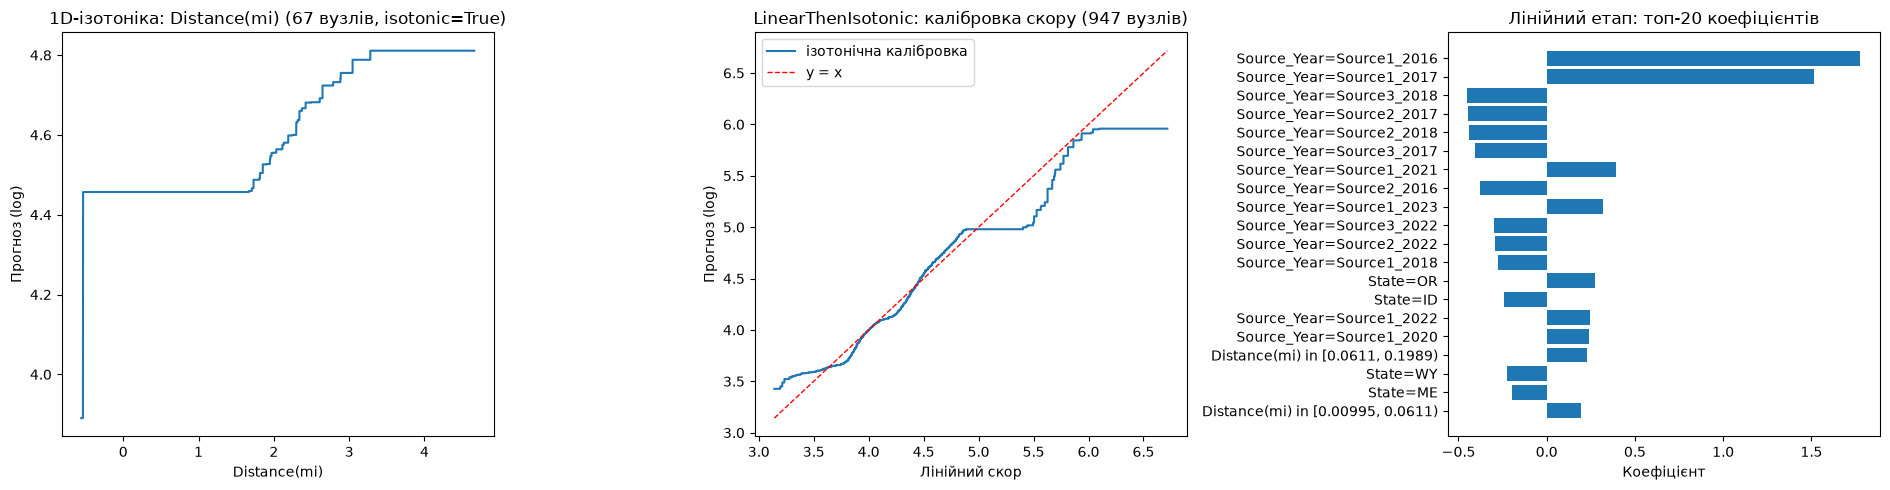

In [12]:
m1 = MODELS[LEADERS['IsotonicRegression']]
m2 = MODELS[LEADERS['LinearThenIsotonic']]
lin_model, iso_model2 = m2.stages[0], m2.stages[-1]
fidx = m1.getFeatureIndex()

fig, axs = plt.subplots(1, 3, figsize=(19, 5))
b, p = m1.boundaries.toArray(), m1.predictions.toArray()
axs[0].plot(b, p)
axs[0].set(title=f'1D-ізотоніка: {FEATURES[fidx]} ({len(b)} вузлів, isotonic={m1.getIsotonic()})',
           xlabel=FEATURES[fidx], ylabel='Прогноз (log)')

b2, p2 = iso_model2.boundaries.toArray(), iso_model2.predictions.toArray()
axs[1].plot(b2, p2, label='ізотонічна калібровка')
axs[1].plot([b2.min(), b2.max()], [b2.min(), b2.max()], 'r--', lw=1, label='y = x')
axs[1].set(title=f'LinearThenIsotonic: калібровка скору ({len(b2)} вузлів)', xlabel='Лінійний скор', ylabel='Прогноз (log)')
axs[1].legend()

coef = lin_model.coefficients.toArray()
top = np.argsort(-np.abs(coef))[:20][::-1]
axs[2].barh([FEATURES[i] for i in top], coef[top])
axs[2].set(title='Лінійний етап: топ-20 коефіцієнтів', xlabel='Коефіцієнт')
plt.tight_layout(); plt.show()

### 6.2 SHAP-аналіз сурогата

Для Spark-моделей немає вбудованого `TreeExplainer`. Тому для кожного лідера навчаємо **лінійну сурогатну модель на його прогнозах** і пояснюємо її `shap.LinearExplainer`. Це **SHAP сурогата**, а не точні SHAP-значення оригінальної Spark-моделі. Показуємо fidelity сурогата (R²); якщо він низький, інтерпретацію вважати ненадійною. Для 1D-моделі це очікувано: вона залежить від однієї ознаки і нелінійно, тому лінійний сурогат відтворить її лише наближено. Для сурогата достатньо 10 тис. рядків train; пояснюємо стратифіковані ~3000 test.

In [13]:
import shap
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from pyspark.ml.functions import vector_to_array

test_strat = bucketizer.transform(data['test'])
sample_frac = min(1.,SHAP_ROWS/max(1,counts['test']))
explain_df = (test_strat.sampleBy('stratum',{float(x):sample_frac for x in strata},SEED)
              .limit(SHAP_ROWS).select('features','label'))
X_test_shap = np.stack([r['a'] for r in explain_df.select(vector_to_array('features').alias('a')).collect()])
assert len(X_test_shap)>0
train_small = data['train'].sample(False,min(1.,10000/max(1,counts['train'])),SEED).limit(10000)
X_bg = np.stack([r['a'] for r in train_small.select(vector_to_array('features').alias('a')).collect()])
print('SHAP test:',len(X_test_shap),'surrogate fit:',len(X_bg))

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP test: 3000 surrogate fit: 10000


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


IsotonicRegression — surrogate fidelity R²=0.943


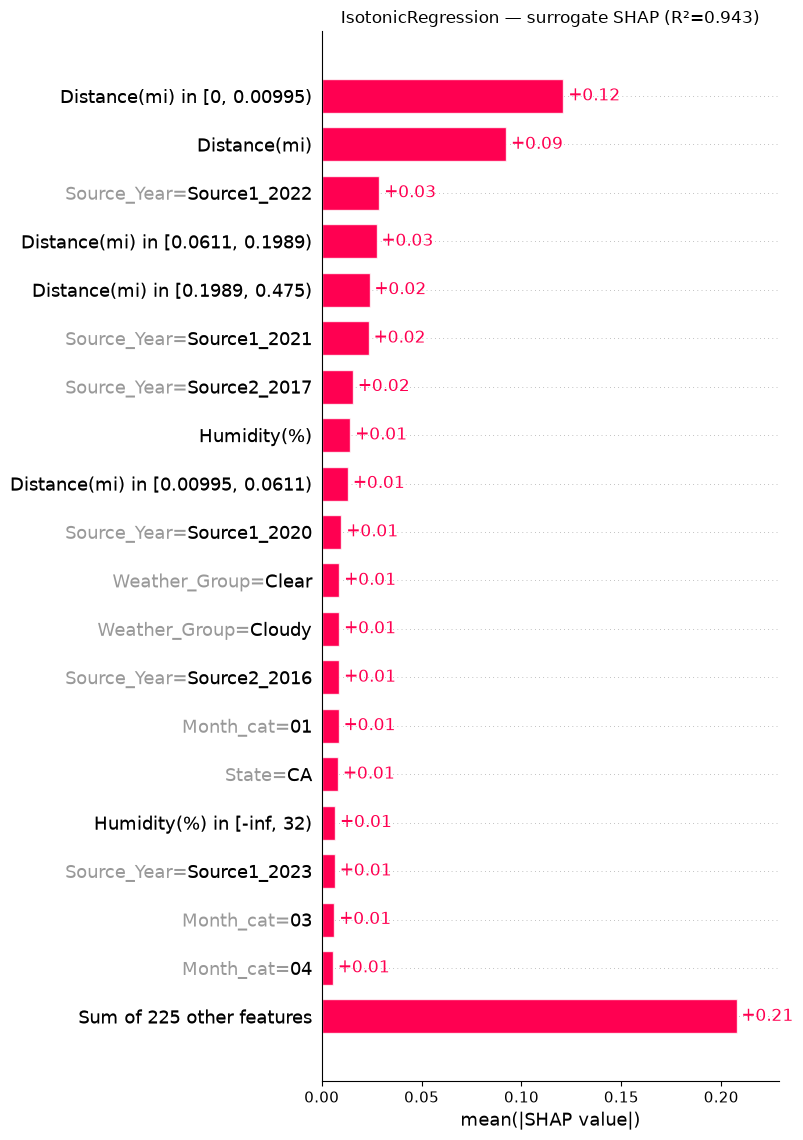

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


LinearThenIsotonic — surrogate fidelity R²=0.982


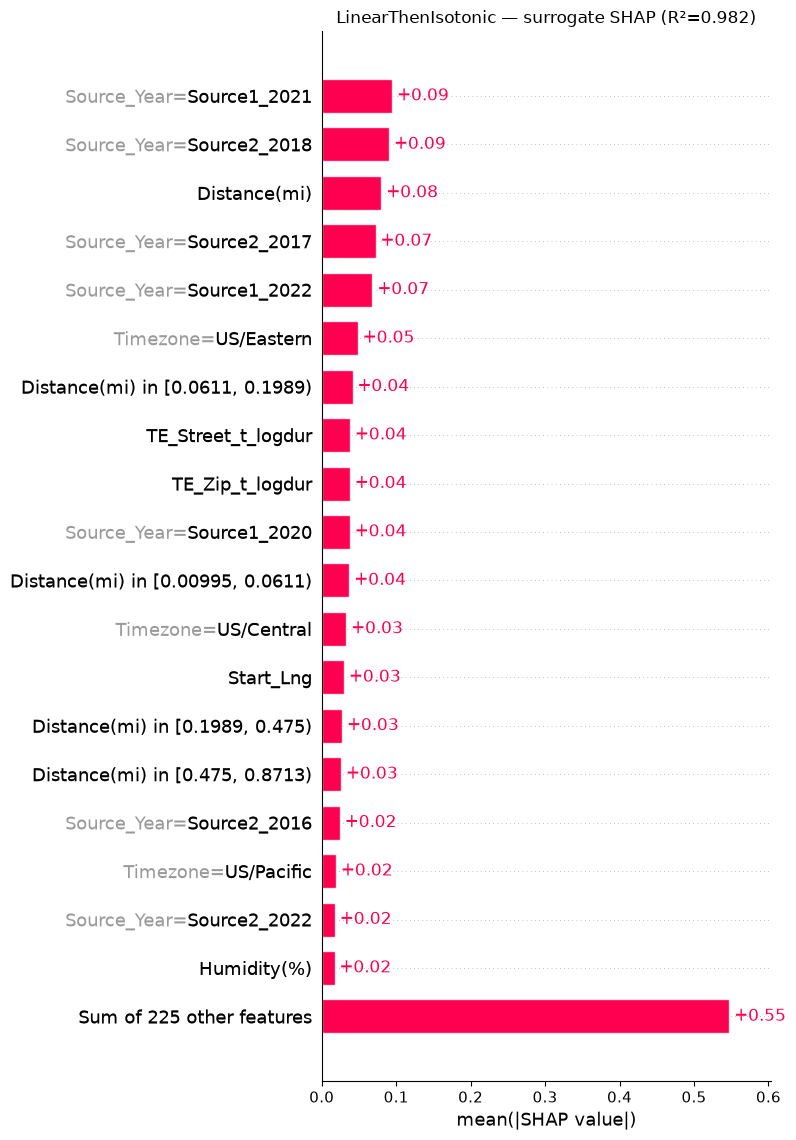

In [14]:
def get_prediction_vectors(model, frame):
    return np.array([r['prediction'] for r in model.transform(frame).select('prediction').collect()])

for fam,name in LEADERS.items():
    model=MODELS[name]
    train_target=get_prediction_vectors(model,train_small)
    test_target=get_prediction_vectors(model,explain_df)
    surrogate=Ridge(alpha=1.).fit(X_bg,train_target)
    fidelity=r2_score(test_target,surrogate.predict(X_test_shap))
    print(f'{fam} — surrogate fidelity R²={fidelity:.3f}')
    explainer=shap.LinearExplainer(surrogate,X_bg[:min(len(X_bg),200)])
    sv=explainer(X_test_shap)
    sv.feature_names=FEATURES
    shap.plots.bar(sv,max_display=20,show=False)
    plt.title(f'{fam} — surrogate SHAP (R²={fidelity:.3f})')
    plt.tight_layout();plt.show()

## Збереження обох лідерів

In [15]:
for fam,name in LEADERS.items():
    path=OUT / ('regression_isotonic_'+fam)
    MODELS[name].write().overwrite().save(str(path))
    print('Збережено:',path)
summary.to_csv(OUT/'regression_isotonic_train_valid_metrics.csv')
TEST_RESULTS.to_csv(OUT/'regression_isotonic_test_metrics.csv')
RANK.to_csv(OUT/'regression_isotonic_feature_screening.csv', index=False)
print('Готово.')

Py4JJavaError: An error occurred while calling o31302.save.
: java.lang.RuntimeException: java.io.FileNotFoundException: Could not locate Hadoop executable: C:\hadoop\bin\winutils.exe -see https://cwiki.apache.org/confluence/display/HADOOP2/WindowsProblems
	at org.apache.hadoop.util.Shell.getWinUtilsPath(Shell.java:790)
	at org.apache.hadoop.util.Shell.getSetPermissionCommand(Shell.java:299)
	at org.apache.hadoop.util.Shell.getSetPermissionCommand(Shell.java:315)
	at org.apache.hadoop.fs.RawLocalFileSystem.setPermission(RawLocalFileSystem.java:1179)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkOneDirWithMode(RawLocalFileSystem.java:861)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirsWithOptionalPermission(RawLocalFileSystem.java:901)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirs(RawLocalFileSystem.java:873)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirsWithOptionalPermission(RawLocalFileSystem.java:900)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirs(RawLocalFi